---
title: "L6-03 · Quantum DAGs and Markov assumptions"
short_title: "Quantum DAGs and Markov assumptions"
subtitle: "In a quantum causal model each node is a place to intervene, each node's parents feed it through a channel, and the process operator is a product of those channels that must commute where they share a parent; with these definitions Markovianity is equivalent to an underlying unitary circuit, and d-separation stays sound and complete for a quantum notion of independence."
description: "State a quantum causal model precisely (nodes, process operator, quantum Markov condition), compute with it, and say which classical graphical conclusions survive and under which definitions."
tags: [level-6, coursebook]
---

(lesson-l6-03)=

:::{div}
:class: qcai-meta
![Level 6 icon](../../_static/icons/qicon-level-6.svg) **Level 6 · Graduate** · about 135 minutes  
**Big idea.** In a quantum causal model each node is a place to intervene, each node's parents feed it through a channel, and the process operator is a product of those channels that must commute where they share a parent; with these definitions Markovianity is equivalent to an underlying unitary circuit, and d-separation stays sound and complete for a quantum notion of independence.  
**Before this lesson.** [L6-01](#lesson-l6-01), [L6-02](#lesson-l6-02), [L4-02](#lesson-l4-02)  
**Lab.** [Quantum causal inference](../../labs/11-quantum-causal-inference.ipynb)
:::

## What you will be able to do

- Write the process operator of a quantum causal model for a given DAG, identify which factors must commute, and compute outcome probabilities with the transposed-instrument rule.
- Show that marginalizing an unintervened middle node of a chain composes the two channels, and that an intervention there changes the effective channel.
- State the equivalence of quantum Markovianity and compatibility with a unitary circuit (Barrett, Lorenz and Oreshkov) and compare it with the classical theorem.
- Distinguish three graph-separation results (Barrett et al., Henson-Lal-Pusey, Pienaar-Brukner) and explain why an absent dependence does not prove an absent arrow.

## Why this matters

In a classical causal model a DAG plus one conditional distribution per node determines a joint distribution, and the graph alone already implies conditional independences through d-separation. It is tempting to take a quantum circuit, draw its DAG, replace every $P(X_i|\mathrm{Pa}(X_i))$ by a density matrix and multiply. That fails at once: density matrices need not commute, their product need not be Hermitian, and there is no joint quantum state of a system at two times. Even the meaning of a node is unclear. Is it a system, an event, a measurement outcome?

Quantum causal models answer these questions with explicit definitions [@allen; @barrett; @costa]. A node is a place where an agent may intervene. What happens between nodes is a process operator, the multi-time generalization of a state built from the Choi operators of [L6-02](#lesson-l6-02). The Markov condition is a factorization into channel operators that must commute, which is the quantum Reichenbach principle of [L6-01](#lesson-l6-01) applied at every node. With those definitions two classical theorems come back: Markovianity is equivalent to an underlying unitary circuit with the graph's structure, and d-separation is sound and complete for a quantum notion of independence [@barrett]. Other classical habits, such as reading an absent arrow off a zero correlation, do not.

:::{dropdown} Key terms

**Quantum node**
: A pair of spaces, an incoming space $A^{\mathrm{in}}$ (from the causal past) and an outgoing space $A^{\mathrm{out}}$ (to the causal future), between which an agent may apply an instrument.

**Process operator**
: A positive operator $\sigma$ on all incoming and outgoing spaces that returns probability 1 for every choice of channels at the nodes; it encodes everything outside the nodes.

**Quantum Markov condition**
: $\sigma_{A_1 \dots A_n} = \prod_i \rho_{A_i|\mathrm{Pa}(A_i)}$ with pairwise commuting channel operators.

**Strong relative independence**
: $Y$ and $Z$ are independent relative to $W$ in $\sigma_{YZW}$ if $\sigma_{YZW} = \alpha_{YW}\,\beta_{ZW}$ for Hermitian $\alpha, \beta$.

**Faithfulness**
: The assumption that every independence in the data is implied by the graph, so that no independence arises from fine-tuned parameters.

**d-separation**
: The graphical criterion that every path between two sets is blocked by the conditioning set, at a non-collider in the set or at a collider with no descendant in the set.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l6_03 as _lessonfigs

## What a classical graph says

:::{prf:definition} Classical Markov condition
:label: def-l6-03-cmarkov
A distribution $P(X_1, \dots, X_n)$ is Markov for a DAG $G$ if $P(X_1, \dots, X_n) = \prod_{i=1}^{n} P(X_i|\mathrm{Pa}(X_i))$ for some conditional distributions [@pearlcausality]. It is compatible with $G$ if it arises from functions $X_i = f_i(\mathrm{Pa}(X_i), U_i)$ with independent noise variables $U_i$; the two notions are equivalent [@pearlcausality; @barrett].
:::

The graph restricts the factorization, not the mechanisms. It fixes which arguments each $P(X_i|\mathrm{Pa}(X_i))$ may have; it does not fix the numbers. An absent arrow is a structural claim (no direct dependence in any mechanism), while a particular choice of conditional distributions can make a present arrow invisible in the data. Allen et al. point out that the cleanest classical analogue of the quantum construction splits each node $X_i$ into an incoming variable $X_i^{I}$ and an outgoing variable $X_i^{O}$, with $P(X_1^{I} \dots X_n^{I}|X_1^{O} \dots X_n^{O}) = \prod_i P(X_i^{I}|\mathrm{Pa}^{O}(X_i))$; an intervention at node $i$ is whatever happens between $X_i^{I}$ and $X_i^{O}$ [@allen].

```{mermaid}
graph LR
  A1["A1"] --> A2["A2"]
  A1 --> A3["A3"]
  A2 --> A4["A4"]
  A3 --> A4
  A1 --> A5["A5"]
  A4 --> A5
```

*The running example, the five-node DAG of Barrett, Lorenz and Oreshkov (their Fig. 5). Node $A_1$ is a parent of three nodes; that is where the quantum Markov condition becomes a nontrivial constraint.*

## Quantum nodes and process operators

:::{prf:definition} Quantum node and process operator
:label: def-l6-03-process
A quantum node $A$ is a pair of Hilbert spaces: an incoming space $\mathcal{H}_{A^{\mathrm{in}}}$ and an outgoing space $\mathcal{H}_{A^{\mathrm{out}}}$ (in Barrett et al. a copy of the dual of the incoming space, so that doing nothing is always possible). A process operator over nodes $A_1, \dots, A_n$ is a positive semidefinite operator $\sigma_{A_1 \dots A_n}$ on $\bigotimes_i \mathcal{H}_{A_i^{\mathrm{in}}} \otimes \mathcal{H}_{A_i^{\mathrm{out}}}$ such that $\operatorname{Tr}[\sigma\, (\tau_{A_1} \otimes \dots \otimes \tau_{A_n})] = 1$ for every choice of channels $\tau_{A_i}$ at the nodes [@barrett]. It follows that tracing out every incoming space leaves the identity on the outgoing spaces.
:::

$$
P(k_1, \dots, k_n) = \operatorname{Tr}\big[\sigma_{A_1 \dots A_n}\, (\tau^{k_1}_{A_1} \otimes \dots \otimes \tau^{k_n}_{A_n})\big], \qquad \tau^{k}_{A} = \big(\rho^{\mathcal{M}_k}_{A|A}\big)^{T}
$$ (eq-l6-03-born)

Here $\{\mathcal{M}_k\}$ is the instrument applied at the node (a collection of CP maps summing to a channel) and $\rho^{\mathcal{M}_k}_{A|A}$ its Choi operator; Barrett et al. use the transposes $\tau^{k}$ so that probabilities come out as a plain trace [@barrett]. Doing nothing at a node is the identity channel, written $\tau^{\mathrm{id}}_A$. In the input-first convention of [L6-02](#lesson-l6-02) (see the dictionary there) the same rule reads $P = \operatorname{Tr}[W\,(J^{k_1} \otimes \dots \otimes J^{k_n})^{T}]$, where $W$ is assembled from the Choi operators of the channels between nodes. That is the link product of L6-02 applied to every wire at once: each connection costs one transpose. The first code cell checks the rule against direct simulation on a chain with random complex channels and instruments.

:::{important} Settings are not nodes here
In the classical Bell graph of [L6-01](#lesson-l6-01), and in the Pienaar-Brukner framework below, the nodes are classical observables (settings and outcomes). In the frameworks of Allen et al. and Barrett et al., a node is a locus of intervention and the setting is the choice of instrument $\{\mathcal{M}_k\}$ applied there; the outcome is $k$. The same experiment therefore has different DAGs in different formalisms. Say which formalism a graph belongs to before reading anything off it.
:::

## The quantum Markov condition

:::{prf:definition} Quantum causal model and quantum Markov condition
:label: def-l6-03-qmarkov
A quantum causal model is a DAG $G$ over quantum nodes $A_1, \dots, A_n$ together with, for each node, a channel $\rho_{A_i|\mathrm{Pa}(A_i)}$ from the outgoing spaces of its parents to its incoming space, such that $[\rho_{A_i|\mathrm{Pa}(A_i)}, \rho_{A_j|\mathrm{Pa}(A_j)}] = 0$ for all $i, j$. A process operator is Markov for $G$ if it equals the product of such commuting channel operators [@allen; @barrett]:

$$\sigma_{A_1 \dots A_n} = \prod_{i=1}^{n} \rho_{A_i|\mathrm{Pa}(A_i)}.$$

Products are padded with identities on the other spaces. Factors on disjoint spaces commute automatically; the condition bites only when two nodes share a parent.
:::

$$
\sigma_{A_1\cdots A_5} = \rho_{A_5|A_1A_4}\, \rho_{A_4|A_2A_3}\, \rho_{A_2|A_1}\, \rho_{A_3|A_1}\, \rho_{A_1}
$$ (eq-l6-03-five)

:::{figure} ../../_static/animations/l6_03_quantum_dag.mp4
:alt: The five-node DAG. Each node is shown as a pair of input and output spaces; the process operator is written factor by factor as each node and its parent edges light up; the three factors that act on the output of A1 are boxed in red with the commutation condition.
:width: 100%

Building [](#eq-l6-03-five) one node at a time. The factors $\rho_{A_5|A_1A_4}$, $\rho_{A_2|A_1}$ and $\rho_{A_3|A_1}$ all act on the output of $A_1$, so they must commute.
:::

:::{dropdown} What the animation shows
The DAG with nodes $A_1$ to $A_5$ and edges $A_1 \to A_2$, $A_1 \to A_3$, $A_2 \to A_4$, $A_3 \to A_4$, $A_1 \to A_5$, $A_4 \to A_5$ is drawn. A small diagram shows a node as two stacked boxes, $A^{\mathrm{in}}$ and $A^{\mathrm{out}}$: a place to intervene, with input from parents and output to children. The process operator is then written term by term while the matching node and its incoming edges are highlighted: $\sigma_{A_1\cdots A_5} = \rho_{A_5|A_1A_4}\, \rho_{A_4|A_2A_3}\, \rho_{A_2|A_1}\, \rho_{A_3|A_1}\, \rho_{A_1}$. Below it, the classical factorization $P(x_5|x_1x_4)P(x_4|x_2x_3)P(x_2|x_1)P(x_3|x_1)P(x_1)$ has the same shape. Finally the three factors that act on the output of $A_1$ are boxed in red and $A_1$ is circled, with the condition $[\rho_{A_i|\mathrm{Pa}(A_i)}, \rho_{A_j|\mathrm{Pa}(A_j)}] = 0$: these factors must commute, so the output of $A_1$ splits, block by block, into one piece per child.
:::


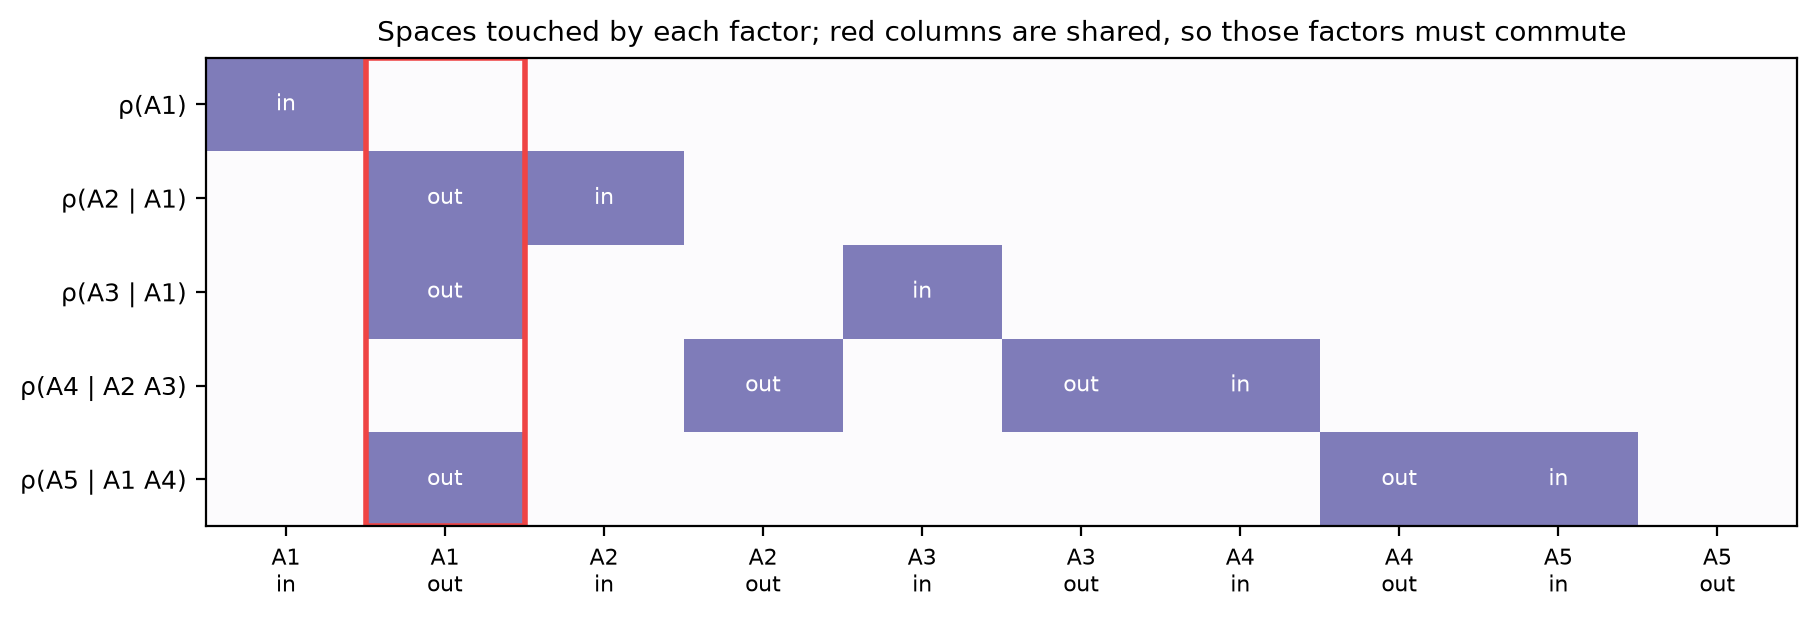

In [2]:
_show_mpl(_lessonfigs.markov_spaces())

*The spaces each factor of [](#eq-l6-03-five) acts on. Only the output of $A_1$ is shared, by three factors; every other pair of factors acts on disjoint spaces and commutes automatically.*

:::{prf:proposition} A parent cannot pass the same quantum system to two children
:label: prop-l6-03-nobroadcast
Let $A$ have a one-qubit output and two children $B$ and $C$, and let both channels be the identity, $\rho_{B|A} = |\Omega\rangle\langle\Omega|_{A^{\mathrm{out}}B} \otimes I_C$ and $\rho_{C|A} = |\Omega\rangle\langle\Omega|_{A^{\mathrm{out}}C} \otimes I_B$. These operators do not commute, and their product is not Hermitian, so no quantum causal model contains both. If instead $A^{\mathrm{out}} = A_1^{\mathrm{out}} A_2^{\mathrm{out}}$ is two qubits, with $B$ fed by $A_1^{\mathrm{out}}$ and $C$ by $A_2^{\mathrm{out}}$, the two factors act on different tensor factors and commute.
:::

:::{prf:proof}
Write $|\Omega\rangle_{A^{\mathrm{out}}B} = |00\rangle + |11\rangle$. Both operators are of the form $P \otimes I$ with $P = |\Omega\rangle\langle\Omega|$ a multiple of a projector on different pairs of qubits sharing $A^{\mathrm{out}}$. With the qubits ordered $A^{\mathrm{out}}, B, C$, the product $\rho_{B|A}\,\rho_{C|A}$ annihilates $|001\rangle$, while $\rho_{C|A}\,\rho_{B|A}$ maps it to $|010\rangle + |111\rangle$ (the second challenge exercise does the computation); the third code cell computes the commutator (largest entry 1) and confirms that the product is not Hermitian. This is the no-cloning theorem in Markov form: by the quantum Reichenbach principle of Allen et al., commuting factors on a shared parent require the decomposition $\mathcal{H}_{A^{\mathrm{out}}} = \bigoplus_i \mathcal{H}_{L_i} \otimes \mathcal{H}_{R_i}$, so each child receives its own piece within each block (or a classical copy of which block).
:::

:::{prf:theorem} Markovianity is equivalent to unitary compatibility (Barrett, Lorenz, Oreshkov)
:label: thm-l6-03-equiv
Call $\sigma_{A_1 \dots A_n}$ compatible with a DAG $G$ if it is the marginal of a process built from a unitary transformation, independent local noise systems $\lambda_1, \dots, \lambda_n$ prepared in product states, and a final output system, such that $A_j$ does not influence $A_i$ whenever $A_j \notin \mathrm{Pa}(A_i)$ and $\lambda_j$ does not influence $A_i$ whenever $j \ne i$. Then $\sigma$ is compatible with $G$ if and only if it is Markov for $G$ [@barrett] (Theorem 4.10 in the arXiv version).
:::

:::{prf:proof}
Sketch. (Compatible implies Markov.) For a unitary channel with several inputs and outputs, if output $B_i$ is influenced only by the inputs in a set $S_i$, then its Choi operator factorizes as $\prod_i \rho_{B_i|S_i}$ with pairwise commuting factors (their Theorem 4.3, a corollary of the main theorem of Allen et al.). Applying this to the underlying unitary with the no-influence conditions of the definition and tracing out the noise and the final output leaves a product of commuting channel operators, one per node with exactly the parents of $G$. (Markov implies compatible.) Given commuting channel operators, Barrett et al. construct a circuit of unitaries with local noise realizing each factor in an order consistent with $G$; the commutation conditions on shared parents are what make the construction possible (their Appendix A). This is the quantum analogue of the classical equivalence between Markovianity and functional models with independent noise.
:::

## Chains, composition and interventions

:::{prf:proposition} An unintervened middle node composes channels
:label: prop-l6-03-chain
Let $\sigma_{ABC} = \rho_{C|B}\,\rho_{B|A}\,\rho_A$ be Markov for the chain $A \to B \to C$, with channels $\mathcal{E}: A^{\mathrm{out}} \to B^{\mathrm{in}}$ and $\mathcal{F}: B^{\mathrm{out}} \to C^{\mathrm{in}}$. With no intervention at $B$,

$$\sigma_{AC} = \operatorname{Tr}_B\big[\sigma_{ABC}\,\tau^{\mathrm{id}}_B\big] = \rho_{C|A}\,\rho_A, \qquad \mathcal{E}_{C|A} = \mathcal{F} \circ \mathcal{E}.$$

If an instrument $\{\mathcal{M}_k\}$ is applied at $B$ and its outcome is ignored, the channel from $A$ to $C$ becomes $\mathcal{F} \circ (\sum_k \mathcal{M}_k) \circ \mathcal{E}$ instead.
:::

:::{prf:proof}
In the input-first convention the relevant operator is $J_{\mathcal{E}} \otimes J_{\mathcal{F}}$ on $A^{\mathrm{out}} B^{\mathrm{in}} B^{\mathrm{out}} C^{\mathrm{in}}$, and doing nothing at $B$ contracts $B^{\mathrm{in}} B^{\mathrm{out}}$ with $(J_{\mathrm{id}})^{T} = |\Omega\rangle\langle\Omega|$. Contracting with $|\Omega\rangle\langle\Omega|$ identifies the index of $B^{\mathrm{in}}$ with that of $B^{\mathrm{out}}$ under a transpose, which is exactly the link product $\operatorname{Tr}_B[(J_{\mathcal{E}}^{T_B} \otimes I)(I \otimes J_{\mathcal{F}})] = J_{\mathcal{F} \circ \mathcal{E}}$ of L6-02. For an instrument, replace $J_{\mathrm{id}}$ by $\sum_k J_{\mathcal{M}_k}$, the Choi operator of the channel $\sum_k \mathcal{M}_k$, and apply the link product twice. The second code cell checks both statements.
:::

:::{figure} ../../_static/animations/l6_03_chain_link.mp4
:alt: Three split nodes A, B, C joined by channel boxes E and F. With the identity plugged into B the marginal becomes the composed channel F after E; then a measurement box at B gives probabilities through transposed Choi operators.
:width: 100%

Doing nothing at $B$ plugs in $\tau^{\mathrm{id}}_B$ and the chain collapses to $\mathcal{F} \circ \mathcal{E}$ by the link product; an intervention at $B$ enters through its transposed Choi operator.
:::

:::{dropdown} What the animation shows
Nodes $A$, $B$, $C$ are drawn as split boxes (in, out) joined by channel boxes $\mathcal{E}$ and $\mathcal{F}$, with $\sigma_{ABC} = \rho_{C|B}\,\rho_{B|A}\,\rho_A$. A violet wire through $B$ marks no intervention, the identity channel. The formula $\sigma_{AC} = \operatorname{Tr}_B[\sigma_{ABC}\,\tau^{\mathrm{id}}_B]$ transforms into $\sigma_{AC} = \rho_{C|A}\,\rho_A$ with $\mathcal{E}_{C|A} = \mathcal{F} \circ \mathcal{E}$, and in the course convention $J_{\mathcal{F}\circ\mathcal{E}} = \operatorname{Tr}_B[(J_{\mathcal{E}}^{T_B} \otimes I)(I \otimes J_{\mathcal{F}})]$, the link product of L6-02. Then an amber box $\mathcal{M}_k$ replaces the wire at $B$: an intervention with outcome $k$. The probability is $P(k) = \operatorname{Tr}[\sigma_{ABC}(\tau_A \otimes \tau^{k}_B \otimes \tau_C)]$ with $\tau^{k}_B = (J_{\mathcal{M}_k})^{T}$: interventions enter through transposed Choi operators.
:::

:::{prf:remark} When the chain picture breaks
The composition $\mathcal{E}_{C|A} = \mathcal{F} \circ \mathcal{E}$ is a consequence of the chain DAG, not of having three time steps. If the system interacts with an environment that keeps a memory between the steps, the correct DAG has an extra node (the environment) that is a common cause of $B$ and $C$, the process operator does not factorize as a chain, and the effective map from $A$ to $C$ need not be a composition of two channels; Allen et al. discuss a non-Markovian example of this kind (their Fig. 11) [@allen].
:::

## Absent arrows and absent dependence

Two directions of inference must be kept apart. An absent arrow implies independences in every model with that graph (that is what Markovianity buys). A present arrow implies nothing about any particular data set: the mechanism can hide it. Prepare $|\varphi\rangle = (|0\rangle + e^{i\varphi}|1\rangle)/\sqrt{2}$, send it through the dephasing channel $\mathcal{D}_p(\rho) = (1 - p/2)\rho + (p/2) Z\rho Z$, and measure $X$:

$$
P(+\,|\,\varphi) = (1 + (1-p)\cos\varphi)/2
$$ (eq-l6-03-hidden)

:::{figure} ../../_static/animations/l6_03_hidden_influence.mp4
:alt: A graph of P(+ given phi) against phi flattens to the constant 1/2 as the dephasing strength p goes from 0 to 1. Then a CNOT circuit with a coin as target: without the coin B carries no information about A, with the coin B copies A's Z value.
:width: 100%

Two ways a present arrow leaves no trace: complete dephasing erases the phase dependence of [](#eq-l6-03-hidden), and the CNOT example of Barrett et al., a one-time pad, hides all signaling unless the coin is known.
:::

:::{dropdown} What the animation shows
First part: the chain $|\varphi\rangle \to \mathcal{D}_p \to$ measure $X$, with a graph of $P(+|\varphi) = (1 + (1-p)\cos\varphi)/2$ for $\varphi$ from 0 to $2\pi$. As $p$ rises from 0 to 1 the cosine curve flattens; at $p = 1$ it is the constant $1/2$, so the outcome does not depend on $\varphi$, but the wire from the preparation to the measurement is still there. Second part: a CNOT with control $A$ and target a coin $\lambda$; the target output is $B$. With the coin unknown, $\rho_{B|A} = I \otimes I/2$ and $A$ cannot signal to $B$. With the coin known, $B$ copies the $Z$ value of $A$ and $A$ signals to $B$ perfectly. The closing text: no signaling is not no influence; an absent dependence does not prove an absent arrow.
:::

:::{prf:example} The one-time pad as a causal example
:label: ex-l6-03-pad
Barrett et al. give this example [@barrett]. Let a CNOT act with control the system from node $A$ and target an unobserved system $\lambda$ prepared by tossing a fair coin and preparing $|0\rangle$ or $|1\rangle$. The output target goes to node $B$. Averaged over the coin, the channel from $A$ to $B$ has $\rho_{B|A} = I \otimes I/2$: it ignores its input. Yet anyone who knows the coin can read $A$'s $Z$ value at $B$. Causal influence is defined on the closed (unitary) description, where the arrow from $A$ to $B$ is present; the absence of signaling in the marginal process is a fine-tuned feature of $\rho_\lambda$.
:::

:::{prf:assumption} Faithfulness, and when it is not available
:label: asm-l6-03-faithful
To infer an absent arrow from an observed independence one needs faithfulness: every independence in the data is implied by the graph. Barrett et al. separate independences forced by Markovianity for $G$ from accidental ones produced by fine-tuned choices of the noise states [@barrett]. Faithfulness is an assumption about the world, not a theorem; in the dephasing example it fails for the pair (relative phase, $X$ outcome) at $p = 1$, while $Z$-basis preparations still pass through the same wire. Structural claims therefore need either informative interventions (vary the preparation and the measurement, as in the exercises) or an explicitly stated faithfulness assumption.
:::

## What survives of d-separation

:::{prf:definition} Strong relative independence of quantum nodes
:label: def-l6-03-sri
For disjoint sets of nodes $Y, Z, W$ and a process operator $\sigma_{YZW}$, write $(Y \perp\!\!\!\perp Z\,|\,W)_\sigma$ if $\sigma_{YZW} = \alpha_{YW}\,\beta_{ZW}$ for some Hermitian operators $\alpha_{YW}$ and $\beta_{ZW}$ [@barrett]. For $W = \emptyset$ this says $\sigma_{YZ} = \sigma_Y \otimes \sigma_Z$, which holds if and only if the outcomes of all local interventions at $Y$ and at $Z$ are independent. For diagonal (classical) process operators it reduces to classical conditional independence.
:::

:::{prf:theorem} Quantum d-separation theorem (Barrett, Lorenz, Oreshkov)
:label: thm-l6-03-dsep
Let $G$ be a DAG over quantum nodes $V$ and let $Y, Z, W$ be disjoint, $R = V \setminus (Y \cup Z \cup W)$ [@barrett] (Theorem 8.3 in the arXiv version).

1. **Soundness.** If $Y$ and $Z$ are d-separated by $W$ in $G$, then for every process operator Markov for $G$ and every local intervention $\tau_R$ at $R$, the marginal $\sigma^{\tau_R}_{YZW}$ satisfies $(Y \perp\!\!\!\perp Z\,|\,W)$.
2. **Completeness.** If they are not d-separated, some process operator Markov for $G$ violates $(Y \perp\!\!\!\perp Z\,|\,W)$ with no intervention at $R$.
:::

:::{prf:proof}
Sketch. The relation $T(Y, Z; W)$, meaning strong relative independence for every local intervention at the remaining nodes, satisfies the semi-graphoid axioms (symmetry, decomposition, weak union, contraction) and, for a Markov process operator, the local Markov property: each node is independent of its non-descendants relative to its parents. A semi-graphoid with the local Markov property makes d-separation sound, by a classical result that Barrett et al. cite. Completeness is inherited from the classical case: a classical distribution that is Markov for $G$ and violates the independence induces a diagonal process operator with the same property [@barrett].
:::


In [3]:
_show(_lessonfigs.dsep_explorer())

**Explore.** Choose a query on the five-node DAG. The conditioning set is amber, the two endpoints violet, and open paths red. By the theorem, the same verdicts hold for strong relative independence in every quantum process operator that is Markov for this DAG.

:::{dropdown} What the figure shows
A drawing of the DAG $A_1 \to A_2$, $A_1 \to A_3$, $A_2 \to A_4$, $A_3 \to A_4$, $A_1 \to A_5$, $A_4 \to A_5$ with a dropdown of queries. $A_2$ and $A_3$ given $A_1$: d-separated. Given nothing: one open path through the fork $A_1$. Given $A_1$ and $A_4$: the collider $A_4$ is opened. Given $A_1$ and $A_5$: $A_5$ is a descendant of the collider $A_4$, so that path opens too. $A_1$ and $A_4$ given $A_2, A_3$: d-separated. $A_2$ and $A_5$ given $A_1, A_4$: d-separated. $A_3$ and $A_5$ given $A_4$: open through $A_3 \leftarrow A_1 \to A_5$.
:::

:::{prf:remark} Three different separation results
Keep three statements apart. (1) Barrett et al.: d-separation is sound and complete for strong relative independence of quantum nodes. Its operational content is one-directional: if $(Y \perp\!\!\!\perp Z\,|\,W)$ holds, there exists a (possibly global) intervention on the $W$ nodes whose outcome renders all local outcomes at $Y$ and $Z$ independent, but such an intervention generally disturbs the process, so it is not a passive conditioning [@barrett]. (2) Henson, Lal and Pusey: in generalized Bayesian networks whose latent nodes may carry quantum or more general resources, d-separation among the observed classical nodes still implies conditional independence [@hlp2014]. (3) Pienaar and Brukner: the nodes are classical observables of a quantum network, and their graph-separation rule does not assume Reichenbach's common cause principle; they prove that it faithfully captures the statistical dependencies between observables in their quantum networks, and it reduces to d-separation in a classical limit [@pienaar].
:::

The three answer different questions. In the Bell scenario of L6-01, $A$ and $B$ have the common parent $C$. Barrett's theorem then guarantees $\sigma_{ABC} = \alpha_{AC}\,\beta_{BC}$, which is the factorization $\rho_{A|C}\,\rho_{B|C}$ of the quantum Reichenbach principle. Henson-Lal-Pusey says nothing about $A$ and $B$ given the unobserved source, because the source is not an observed classical node. Pienaar-Brukner, which does not assume the common cause principle, does not declare the outcomes conditionally independent given the source. None of these contradicts the Bell violation; each is a precise statement about a different object. Costa and Shrapnel give another process-based definition of quantum causal models with its own Markov condition; it is related to, but not identical with, the one used here [@costa].

## Compute it

A chain $A \to B \to C$ with random complex channels: the process operator is normalized, and outcome probabilities of instruments at the three nodes follow $\operatorname{Tr}[W (J_A \otimes J_B \otimes J_C)^{T}]$. Without the transpose the rule fails.


In [4]:
import itertools, math
import numpy as np
from qcai import science as s

rng = np.random.default_rng(11)

def choi_of(E, d=2):
    """Course convention (L6-02): sum_ij |i><j| (x) E(|i><j|), input factor first."""
    J = 0
    for i in range(d):
        for j in range(d):
            Eij = np.zeros((d, d), dtype=complex)
            Eij[i, j] = 1
            J = J + np.kron(Eij, E(Eij))
    return J

def random_channel(m=2):
    G = rng.normal(size=(2 * m, 2)) + 1j * rng.normal(size=(2 * m, 2))
    V = np.linalg.qr(G)[0].reshape(2, m, 2)
    K = [V[:, k, :] for k in range(m)]
    return lambda X: sum(k @ X @ k.conj().T for k in K)

# chain A -> B -> C; each node has an input and an output qubit; factor order Ai Ao Bi Bo Ci Co
G0 = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2))
rho = G0 @ G0.conj().T / np.trace(G0 @ G0.conj().T)          # what arrives at A
E, F = random_channel(), random_channel()                        # A -> B and B -> C
W = np.kron(np.kron(np.kron(rho, choi_of(E)), choi_of(F)), np.eye(2))   # process operator, course convention
Wt = W.reshape([2] * 12)
print('Tr over all inputs gives I on all outputs:',
      np.allclose(np.einsum('aAbBcCaDbEcF->ABCDEF', Wt).reshape(8, 8), np.eye(8)))

# instruments at the three nodes (measure-and-prepare maps and a random two-outcome instrument)
mp = lambda proj, prep: (lambda X: np.trace(proj @ X) * prep)
P0, P1 = s.dm(s.KET0), s.dm(s.KET1)
pi_, mi_ = s.dm(np.array([1, 1j]) / math.sqrt(2)), s.dm(np.array([1, -1j]) / math.sqrt(2))
IA = [mp(P0, pi_), mp(P1, s.dm(np.array([math.cos(0.4), math.sin(0.4) * np.exp(0.9j)])))]
G1 = rng.normal(size=(4, 2)) + 1j * rng.normal(size=(4, 2))
V = np.linalg.qr(G1)[0]
IB = [lambda X, K=V[:2]: K @ X @ K.conj().T, lambda X, K=V[2:]: K @ X @ K.conj().T]
IC = [mp(pi_, P0), mp(mi_, P0)]                                  # measure Y at C, prepare |0>
err_T, err_noT = 0.0, 0.0
for a, b, c in itertools.product(range(2), repeat=3):
    T = np.kron(np.kron(choi_of(IA[a]), choi_of(IB[b])), choi_of(IC[c]))
    direct = np.trace(IC[c](F(IB[b](E(IA[a](rho)))))).real
    err_T = max(err_T, abs(np.trace(W @ T.T).real - direct))
    err_noT = max(err_noT, abs(np.trace(W @ T).real - direct))
print('P(kA,kB,kC) = Tr[W (J_A (x) J_B (x) J_C)^T]: max error', f'{err_T:.1e}')
print('same rule without the transpose:            max error', f'{err_noT:.3f}')

Tr over all inputs gives I on all outputs: True
P(kA,kB,kC) = Tr[W (J_A (x) J_B (x) J_C)^T]: max error 5.6e-17
same rule without the transpose:            max error 0.064


Marginalizing $B$ with $\tau^{\mathrm{id}}_B$ composes the channels; a non-selective $Z$ measurement at $B$ gives $\mathcal{F} \circ \mathcal{D} \circ \mathcal{E}$ instead.


In [5]:
def link_middle(M):
    """Contract B (input and output) of an operator on Ao Bi Bo Ci with tau_id = J_id^T: no intervention at B."""
    T = np.kron(np.kron(np.eye(2), choi_of(lambda X: X).T), np.eye(2))
    return np.einsum('abcdebcf->adef', (M @ T).reshape([2] * 8)).reshape(4, 4)

JE, JF = choi_of(E), choi_of(F)
print('no intervention at B: marginal = Choi of F o E:', np.allclose(link_middle(np.kron(JE, JF)), choi_of(lambda X: F(E(X)))))

# a non-selective Z measurement at B instead: the effective channel from A to C is F o D o E
D = lambda X: np.diag(np.diag(X))
T_D = np.kron(np.kron(np.eye(2), choi_of(D).T), np.eye(2))
J_eff = np.einsum('abcdebcf->adef', (np.kron(JE, JF) @ T_D).reshape([2] * 8)).reshape(4, 4)
print('Z measurement at B: effective channel = F o D o E:', np.allclose(J_eff, choi_of(lambda X: F(D(E(X))))))
print('and it differs from F o E:', not np.allclose(J_eff, choi_of(lambda X: F(E(X)))))

no intervention at B: marginal = Choi of F o E: True
Z measurement at B: effective channel = F o D o E: True
and it differs from F o E: True


Commutation on a shared parent (no-cloning in Markov form), the CNOT one-time pad, and the dephasing example of [](#eq-l6-03-hidden).


In [6]:
def reorder(M, perm, dims):
    n = len(dims)
    return M.reshape(dims + dims).transpose(perm + [p + n for p in perm]).reshape(M.shape)

Om = choi_of(lambda X: X)                                        # identity channel, |Omega><Omega|
# parent A (one output qubit Ao) with two children B and C; factor order Ao B C
J_B = np.kron(Om, np.eye(2))                                     # identity Ao -> B
J_C = reorder(np.kron(Om, np.eye(2)), [0, 2, 1], [2, 2, 2])      # identity Ao -> C
print('identity to both children: commutator', np.abs(J_B @ J_C - J_C @ J_B).max(),
      ' product Hermitian:', np.allclose(J_B @ J_C, (J_B @ J_C).conj().T))

# split parent: Ao = Ao1 Ao2, B reads Ao1 and C reads Ao2; factor order Ao1 Ao2 B C
J_B2 = reorder(np.kron(np.kron(Om, np.eye(2)), np.eye(2)), [0, 2, 1, 3], [2, 2, 2, 2])
J_C2 = reorder(np.kron(np.kron(np.eye(2), np.eye(2)), Om), [0, 2, 1, 3], [2, 2, 2, 2])
print('split parent: commutator', np.abs(J_B2 @ J_C2 - J_C2 @ J_B2).max())

# the CNOT one-time pad: control A, target a coin lambda, B = target output
CN = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]])
pad = lambda lam: (lambda X: np.einsum('aiaj->ij', (CN @ np.kron(X, lam) @ CN.T).reshape(2, 2, 2, 2)))
print('coin unknown, rho_B|A = I (x) I/2:', np.allclose(choi_of(pad(np.eye(2) / 2)), np.kron(np.eye(2), np.eye(2) / 2)))
print('coin known (|0>), rho_B|A =', np.round(choi_of(pad(P0)).real, 3).diagonal(), 'on the diagonal: Z value copied')

# hidden influence: dephasing D_p, then an X measurement of (|0> + e^{i phi}|1>)/sqrt 2
for p in (0.0, 0.5, 1.0):
    vals = []
    for ph in (0.0, math.pi / 2, math.pi):
        out = s.apply_kraus(s.dm(np.array([1, np.exp(1j * ph)]) / math.sqrt(2)), s.dephasing_kraus(p))
        vals.append(np.real(np.array([1, 1]) @ out @ np.array([1, 1])) / 2)
    print(f'p = {p}: P(+|phi) at phi = 0, pi/2, pi:', np.round(vals, 3), ' formula:', np.round([(1 + (1 - p) * math.cos(t)) / 2 for t in (0, math.pi / 2, math.pi)], 3))

identity to both children: commutator 1.0  product Hermitian: False
split parent: commutator 0.0
coin unknown, rho_B|A = I (x) I/2: True
coin known (|0>), rho_B|A = [1. 0. 0. 1.] on the diagonal: Z value copied
p = 0.0: P(+|phi) at phi = 0, pi/2, pi: [1.  0.5 0. ]  formula: [1.  0.5 0. ]
p = 0.5: P(+|phi) at phi = 0, pi/2, pi: [0.75 0.5  0.25]  formula: [0.75 0.5  0.25]
p = 1.0: P(+|phi) at phi = 0, pi/2, pi: [0.5 0.5 0.5]  formula: [0.5 0.5 0.5]


The d-separation verdicts of the interactive figure, computed with `networkx`.


In [7]:
import networkx as nx

G = nx.DiGraph([('A1', 'A2'), ('A1', 'A3'), ('A2', 'A4'), ('A3', 'A4'), ('A1', 'A5'), ('A4', 'A5')])
dsep = getattr(nx, 'is_d_separator', None) or nx.d_separated
for x, y, z in [('A2', 'A3', {'A1'}), ('A2', 'A3', set()), ('A2', 'A3', {'A1', 'A4'}), ('A2', 'A3', {'A1', 'A5'}),
                ('A1', 'A4', {'A2', 'A3'}), ('A3', 'A5', {'A4'})]:
    print(f'{x} and {y} given {sorted(z) or "nothing"}: d-separated = {dsep(G, {x}, {y}, z)}')

A2 and A3 given ['A1']: d-separated = True
A2 and A3 given nothing: d-separated = False
A2 and A3 given ['A1', 'A4']: d-separated = False
A2 and A3 given ['A1', 'A5']: d-separated = False
A1 and A4 given ['A2', 'A3']: d-separated = True
A3 and A5 given ['A4']: d-separated = False


## Worked example

:::{admonition} Composing a dephasing and a depolarizing step
:class: tip

In the chain $A \to B \to C$, the channel into $B$ is the dephasing channel $\mathcal{D}_p$ and the channel into $C$ is the depolarizing channel $\mathcal{N}_q(\rho) = (1-q)\rho + q I/2$. With no intervention at $B$, find the channel from $A$ to $C$, its Bloch scalings and the eigenvalues of its Choi operator. Then find the channel when $B$ measures $Z$ and forgets the outcome.

1. By the chain proposition, no intervention at $B$ gives $\mathcal{E}_{C|A} = \mathcal{N}_q \circ \mathcal{D}_p$. Dephasing scales the Bloch vector by $(1-p, 1-p, 1)$ and depolarizing by $(1-q)$ in every direction, so the composition scales by $\lambda = ((1-p)(1-q),\ (1-p)(1-q),\ 1-q)$.
2. Both channels are Pauli channels, so the composition is the Pauli channel with these scalings. By the Pauli-tetrahedron proposition of [L6-02](#lesson-l6-02) its Choi eigenvalues are $2p_k$ with $p_0 = \tfrac14(1 + \lambda_x + \lambda_y + \lambda_z)$, $p_x = p_y = \tfrac14(1 - \lambda_z)$ and $p_z = \tfrac14(1 - 2\lambda_x + \lambda_z)$, using $\lambda_x = \lambda_y$.
3. For $p = 0.5$ and $q = 0.2$: $\lambda = (0.4, 0.4, 0.8)$, so $p_0 = 0.65$, $p_x = p_y = 0.05$, $p_z = 0.25$; the eigenvalues of $J$ are $1.3, 0.1, 0.1, 0.5$, all positive, with sum 2.
4. A non-selective $Z$ measurement at $B$ is the completely dephasing channel $\mathcal{D}_1$, so the effective channel becomes $\mathcal{N}_q \circ \mathcal{D}_1 \circ \mathcal{D}_p$ with scalings $(0, 0, 1-q) = (0, 0, 0.8)$: every relative phase prepared at $A$ is lost, whatever $p$ was.

**Result.** Without intervention the chain is a Pauli channel with $\lambda = (0.4, 0.4, 0.8)$ and Choi eigenvalues $1.3, 0.1, 0.1, 0.5$; measuring $Z$ at $B$ changes it to $\lambda = (0, 0, 0.8)$. The intervention at the middle node changes the effective causal mechanism from $A$ to $C$.
:::

## Exercises

**1. (Core)** Write the process operator of a quantum causal model for the DAG $A \to B$, $A \to C$, $B \to C$ (a confounded cause and effect). Which pairs of factors act on a common space, and what does the commutation condition demand?

:::{dropdown} Solution
$\sigma_{ABC} = \rho_{C|AB}\,\rho_{B|A}\,\rho_A$. $\rho_A$ acts on $A^{\mathrm{in}}$ only and commutes with everything. $\rho_{B|A}$ acts on $A^{\mathrm{out}} B^{\mathrm{in}}$ and $\rho_{C|AB}$ on $A^{\mathrm{out}} B^{\mathrm{out}} C^{\mathrm{in}}$; they share $A^{\mathrm{out}}$ and must commute. By the quantum Reichenbach principle this forces $\mathcal{H}_{A^{\mathrm{out}}} = \bigoplus_i \mathcal{H}_{L_i} \otimes \mathcal{H}_{R_i}$ with $\rho_{B|A}$ reading only the $L$ pieces and $\rho_{C|AB}$ only the $R$ pieces (and which block $i$): in words, a possibly degenerate measurement on $A$'s output, then one piece goes to $B$ and the other is recombined with $B$'s output at $C$. Allen et al. discuss this example (their Fig. 10).
:::

**2. (Core)** In the dephasing example with $p = 1$, the $X$ outcome does not depend on the prepared phase $\varphi$. Design a different preparation at $A$ that reveals the arrow from $A$ to the measurement, and compute the dependence.

:::{dropdown} Solution
Complete dephasing keeps diagonal entries. Prepare $|0\rangle$ or $|1\rangle$ at $A$ and measure $Z$: the outcome equals the preparation with probability 1, since $\mathcal{D}_1(|j\rangle\langle j|) = |j\rangle\langle j|$. So $P(z = j|\text{prepared } j) = 1$, maximal dependence. Independence held only for the family of equatorial preparations and an $X$ measurement; it was a property of that experiment, not of the graph.
:::

**3. (Stretch)** Prove that the marginal of a chain with no intervention at $B$ is the composed channel, in the input-first convention: show that contracting $J_{\mathcal{E}} \otimes J_{\mathcal{F}}$ on $B^{\mathrm{in}} B^{\mathrm{out}}$ with $|\Omega\rangle\langle\Omega|$ gives $J_{\mathcal{F} \circ \mathcal{E}}$.

:::{dropdown} Solution
Write $J_{\mathcal{E}} = \sum_{ij} |i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ and $J_{\mathcal{F}} = \sum_{kl} |k\rangle\langle l| \otimes \mathcal{F}(|k\rangle\langle l|)$, and $|\Omega\rangle\langle\Omega| = \sum_{mn} |m\rangle\langle n| \otimes |m\rangle\langle n|$ on $B^{\mathrm{in}} B^{\mathrm{out}}$. The contraction is $\operatorname{Tr}_{B^{\mathrm{in}}B^{\mathrm{out}}}[(J_{\mathcal{E}} \otimes J_{\mathcal{F}})(I \otimes |\Omega\rangle\langle\Omega| \otimes I)]$. For fixed $i, j, k, l$ the $B^{\mathrm{in}}$ trace gives $\langle n|\mathcal{E}(|i\rangle\langle j|)|m\rangle$ and the $B^{\mathrm{out}}$ trace gives $\langle n|k\rangle\langle l|m\rangle = \delta_{nk}\delta_{lm}$. Summing over $m, n$ leaves $\langle k|\mathcal{E}(|i\rangle\langle j|)|l\rangle$, and summing over $k, l$ gives $\sum_{kl} \langle k|\mathcal{E}(|i\rangle\langle j|)|l\rangle\, \mathcal{F}(|k\rangle\langle l|) = \mathcal{F}(\mathcal{E}(|i\rangle\langle j|))$. Hence the result is $\sum_{ij} |i\rangle\langle j| \otimes \mathcal{F}(\mathcal{E}(|i\rangle\langle j|)) = J_{\mathcal{F}\circ\mathcal{E}}$; the second code cell confirms it numerically.
:::

**4. (Stretch)** On the five-node DAG, decide whether $A_2$ and $A_3$ are d-separated by $\{A_1, A_5\}$. State precisely what the quantum d-separation theorem then guarantees or fails to guarantee for a process operator Markov for the DAG.

:::{dropdown} Solution
The paths from $A_2$ to $A_3$ are $A_2 \leftarrow A_1 \to A_3$ (blocked: $A_1$ is a conditioned non-collider), $A_2 \to A_4 \leftarrow A_3$ (collider $A_4$ not conditioned, but its descendant $A_5$ is, so the path is open), and $A_2 \to A_4 \to A_5 \leftarrow A_1 \to A_3$ (blocked at $A_1$). One open path, so not d-separated. By completeness there exists a process operator Markov for the DAG whose marginal $\sigma_{A_2A_3A_1A_5}$, with no intervention at $A_4$, violates strong relative independence of $A_2$ and $A_3$ relative to $\{A_1, A_5\}$. Soundness gives nothing here. The theorem does not say that every Markov process operator violates it; a fine-tuned one may not.
:::

**5. (Challenge)** Show that the operators of the no-broadcasting proposition do not commute by evaluating both products on a basis vector, and explain how the quantum Reichenbach principle of Allen et al. rules out every pair of children that both receive the whole qubit coherently.

:::{dropdown} Solution
Order the qubits $A, B, C$ and write $P_{AB} = |\Omega\rangle\langle\Omega|_{AB} \otimes I_C$, $P_{AC} = |\Omega\rangle\langle\Omega|_{AC} \otimes I_B$. On $|0\rangle|0\rangle|1\rangle$: $P_{AC}|001\rangle = |\Omega\rangle_{AC}\langle\Omega|01\rangle_{AC}|0\rangle_B = 0$, so $P_{AB}P_{AC}|001\rangle = 0$; but $P_{AB}|001\rangle = (|00\rangle + |11\rangle)_{AB}|1\rangle_C$, and $P_{AC}$ maps this to $|0\rangle_B|\Omega\rangle_{AC}\langle\Omega|01\rangle + |1\rangle_B|\Omega\rangle_{AC}\langle\Omega|11\rangle = |1\rangle_B(|00\rangle + |11\rangle)_{AC}$, which is nonzero. So $P_{AC}P_{AB} \ne P_{AB}P_{AC}$. In general, commuting factors $\rho_{B|A}, \rho_{C|A}$ on a shared parent output are equivalent (Allen et al.) to a decomposition $\bigoplus_i \mathcal{H}_{L_i} \otimes \mathcal{H}_{R_i}$ with $B$ reading only $L_i$ and $C$ only $R_i$. If both children received the whole qubit coherently, both channels would be faithful on a two-dimensional block that cannot be split into two nontrivial tensor factors, which is impossible; at most the block label (classical information) can go to both.
:::

**6. (Challenge)** In the CNOT one-time pad, compute $\rho_{B|A}$ when the coin is prepared in $|0\rangle$, in $|1\rangle$, and in $I/2$, and explain why the definition of causal influence in Barrett et al. counts an arrow from $A$ to $B$ although the marginal process shows no signaling.

:::{dropdown} Solution
With target $|0\rangle$ the target output is $|a\rangle$ for control $|a\rangle$, and coherences of the control are destroyed in the target alone: $\mathcal{E}_0(X) = \sum_a \langle a|X|a\rangle\, |a\rangle\langle a|$, so $\rho_{B|A} = |00\rangle\langle 00| + |11\rangle\langle 11|$ (diagonal $1, 0, 0, 1$, as the code prints). With $|1\rangle$, $\rho_{B|A} = |01\rangle\langle 01| + |10\rangle\langle 10|$. With $I/2$, the average is $\tfrac12 I \otimes I = I \otimes I/2$, the replacement channel. Barrett et al. define influence on the underlying unitary: $A$ influences $B$ if the marginal channel of the unitary to $B$ depends on the input at $A$ for some state of the other inputs. For the CNOT it does (take $\lambda = |0\rangle$), so the arrow is present; the absence of signaling for $\rho_\lambda = I/2$ is a fine-tuned property of that noise state.
:::

## Check your understanding

**1. Besides the product form $\prod_i \rho_{A_i|\mathrm{Pa}(A_i)}$, what does the quantum Markov condition of Allen et al. and Barrett et al. require?**

- **A.** The process operator has trace 1
- **B.** Every channel is unitary
- **C.** Every node has at most one parent
- **D.** The channel operators commute pairwise

:::{dropdown} Show the answer
**D. The channel operators commute pairwise**

Without commutation the product need not be Hermitian or positive. Commutation is automatic for factors on disjoint spaces and is a real constraint when nodes share a parent.
:::

**2. In the chain $A \to B \to C$, nothing is done at $B$. What is the channel from $A$ to $C$?**

- **A.** The channel into $C$ alone
- **B.** The composition of the channel into $C$ after the channel into $B$
- **C.** The product of the two Choi operators without any contraction
- **D.** It is undefined because $B$ is not measured

:::{dropdown} Show the answer
**B. The composition of the channel into $C$ after the channel into $B$**

Doing nothing is the identity instrument $\tau^{\mathrm{id}}_B$, and contracting with it is the link product, which gives $J_{\mathcal{F} \circ \mathcal{E}}$.
:::

**3. For one preparation family and one measurement, the outcome at $C$ is independent of the setting at $A$. What can be concluded about the arrow from $A$ to $C$?**

- **A.** The arrow is absent
- **B.** Nothing without further interventions or a faithfulness assumption
- **C.** The process is not Markov
- **D.** The arrow is present

:::{dropdown} Show the answer
**B. Nothing without further interventions or a faithfulness assumption**

A present mechanism can hide its influence for particular preparations, as complete dephasing and the CNOT one-time pad show. Absent arrows imply independences; the converse needs faithfulness.
:::

**4. In the DAG $A \to C \leftarrow B$, what does conditioning on $C$ do to the relation between $A$ and $B$?** *(Review of [L4-02](#lesson-l4-02))*

- **A.** It reverses the arrows
- **B.** It can make them dependent
- **C.** Nothing, because they share no parent
- **D.** It makes them independent

:::{dropdown} Show the answer
**B. It can make them dependent**

$C$ is a collider. Unconditioned it blocks the path and $A, B$ are d-separated; conditioning on it (or on a descendant) opens the path.
:::

## Common misconceptions

- **"A quantum causal model is a classical one with density matrices in place of conditional probabilities."** The factors are channel operators on input and output spaces, they must commute, and probabilities come from instruments through the transposed-Choi rule. Multiplying density matrices along a DAG gives operators that are generally not even Hermitian.
- **"d-separation fails for quantum systems."** It depends on the notion of independence. For strong relative independence of quantum nodes it is sound and complete (Barrett et al.), and for observed classical nodes it holds in any generalized probabilistic theory (Henson-Lal-Pusey). What fails is screening off by conditioning on a classical description of a quantum common cause.
- **"If $A$ cannot signal to $B$, there is no arrow from $A$ to $B$."** The one-time pad and complete dephasing are counterexamples: influence is defined on the underlying unitary description, and its absence from the statistics can be a fine-tuned property of unobserved states.

:::{caution} Scope and limits
This lesson follows the definitions of Allen et al. and Barrett, Lorenz and Oreshkov; theorem numbers refer to the arXiv versions. Costa and Shrapnel, Pienaar and Brukner, and Henson, Lal and Pusey use related but different definitions, and their results do not transfer without translation. All results assume finite dimensions, a DAG (no cycles, a definite causal order), and, for the equivalence theorem, unitary underlying dynamics with independent local noise. The operational meaning of strong relative independence is only partial (an existence statement about interventions). Numerical checks here are exact linear algebra, not experiments or statistical tests.
:::

:::{seealso} Where this leads
Interventions at quantum nodes, and the quantum analogues of the do-calculus that Barrett et al. prove, are the subject of [L6-04](#lesson-l6-04). [L6-05](#lesson-l6-05) asks what structure can be learned from interventional data. [L6-07](#lesson-l6-07) drops the DAG altogether and asks which process operators are valid without a fixed causal order, and Lab 11 compares common-cause and cause-effect signatures in a fixed protocol.
:::

:::{dropdown} For instructors

**Why this lesson.** Students who know Pearl's framework need to see which of its theorems survive in quantum theory and why. Precise definitions (node, process operator, commuting factors) turn vague analogies into checkable statements, and the transposed-instrument rule ties the formalism to the Choi calculus of L6-02 [@barrett; @allen; @pienaar].

**Teaching notes.**

- Start with the failed naive attempt: multiply two non-commuting density matrices and show the product is not Hermitian; then introduce channel operators and commutation.
- Use the space table figure to show that commutation matters only at shared parents; ask students to predict which factors must commute for their own DAGs.
- Run the first code cell with the transpose removed (it is printed) to make the convention concrete before discussing the formal rule.
- Assign the three-separation-results remark as a reading exercise: for each, students state the objects (quantum nodes, observed classical nodes, settings and outcomes) and the notion of independence.

**Assessment.** The core exercises test model writing and the faithfulness argument; the stretch exercises test the composition proof and a d-separation query with a descendant of a collider; the challenges test no-broadcasting from commutation and the definition of influence.

**Going further.** Barrett, Lorenz and Oreshkov also prove quantum analogues of the three rules of the do-calculus; read their Sections 9 and 10 alongside [L6-04](#lesson-l6-04) [@barrett]. Pienaar and Brukner's q-separation and the Henson-Lal-Pusey framework make an instructive comparison of what is treated as a node [@pienaar; @hlp2014]. Chiribella, D'Ariano and Perinotti's quantum combs give the mathematical background for process operators [@chiribella].

:::

## References

This lesson draws on [@barrett; @allen; @pienaar; @hlp2014; @costa; @pearlcausality; @chiribella].

**Further reading.**

- [@barrett]: Sections 3, 4 and 8: definitions, the compatibility theorem, and quantum d-separation.
- [@pienaar]: q-separation for settings and outcomes, without the common-cause factorization.
- [@costa]: A process-matrix-based definition of quantum causal models.
- [@leifer]: Quantum conditional states as a causally neutral language for inference.

**Next:** [L6-04 · Operational interventions](#lesson-l6-04)
